# Figure 3 — EC across parcellations
Run the cells in order to reproduce the final eight-panel group-level figure. Loads the saved REST1 mOU estimates, maps 200 → 100 by the original atlas-overlap rule, then averages connection blocks for 100 → 62. No model fitting, fingerprinting, atlas downloads, or exploratory plots.

The saved final figure used the 200-ROI arrays filtered by the original max-weight rule in both runs: exclude a subject if max(EC) < 0.03 in either run. This retains 953 estimates at 200 ROIs; 62- and 100-ROI means use 1013 estimates. The later exploratory load of EC_matrix_HCP1_200_converged.npy is not used. Group means and plotting conventions are preserved. These are separate group averages, not a matched-subject comparison across resolutions.


In [2]:
from pathlib import Path
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from scipy.io import loadmat
from scipy.stats import linregress
from mpl_toolkits.axes_grid1 import make_axes_locatable

PROJECT = Path.home() / 'Scripts/Insight_project'
DATA = PROJECT / 'numpy files'
OUTPUT = PROJECT / 'Figures'
OUTPUT.mkdir(exist_ok=True)
ATLAS_ROOT = Path('/home/allegra/atlases')
plt.style.use('default')
font_file = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
fm.fontManager.addfont(font_file)
plt.rcParams['font.family'] = fm.FontProperties(fname=font_file).get_name()

def dediag(matrix):
    matrix = np.array(matrix, copy=True)
    np.fill_diagonal(matrix, 0)
    return matrix


In [3]:
JS_62_1 = np.load(DATA / 'EC_matrix_HCP1_74.npy', mmap_mode='r')[:, :62, :62]
JS_100_1 = np.load(DATA / 'JS_1_100_new.npy', mmap_mode='r')[:, :100, :100]
JS_200_1 = np.load(DATA / 'JS_1_200_new.npy', mmap_mode='r')
JS_200_2 = np.load(DATA / 'JS_2_200_new.npy', mmap_mode='r')
keep_200 = (np.max(JS_200_1, axis=(1, 2)) >= 0.03) & (np.max(JS_200_2, axis=(1, 2)) >= 0.03)
JS_new = JS_200_1[keep_200, :200, :200]
assert JS_62_1.shape == (1013, 62, 62)
assert JS_100_1.shape == (1013, 100, 100)
assert JS_new.shape == (953, 200, 200)
aggregate = loadmat(PROJECT / 'clust_idx_LEMON.mat')['clust_idx_LEMON'].reshape(-1)[:100]
assert np.array_equal(np.unique(aggregate), np.arange(1, 63))
print('Group sizes:', len(JS_62_1), len(JS_100_1), len(JS_new))


Group sizes: 1013 1013 953


## Coarse graining
The 200 → 100 assignment uses the most frequent nonzero Schaefer-100 label overlapping each Schaefer-200 parcel. Connectivity reductions average all entries in the corresponding blocks. Diagonal handling and averaging order match the original final figure.

In [5]:
schaefer100 = nib.load(ATLAS_ROOT / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii').get_fdata().astype(int).squeeze()
schaefer200 = nib.load(ATLAS_ROOT / 'Schaefer2018_200Parcels_7Networks_order.dlabel.nii').get_fdata().astype(int).squeeze()
assert schaefer100.shape == schaefer200.shape
mapping = {}
for parcel in np.unique(schaefer200[schaefer200 > 0]):
    overlapping = schaefer100[schaefer200 == parcel]
    overlapping = overlapping[overlapping > 0]
    if not overlapping.size:
        raise ValueError(f'No valid overlap for parcel {parcel}')
    mapping[int(parcel)] = int(np.bincount(overlapping).argmax())
assert len(mapping) == 200 and set(mapping.values()) == set(range(1, 101))
roi100 = sorted(set(mapping.values()))
roi200_by_100_idx = {label: [parcel - 1 for parcel, target in mapping.items() if target == label] for label in roi100}

def mapping_orig(C200):
    C100 = np.zeros((100, 100))
    for i, a in enumerate(roi100):
        for j, b in enumerate(roi100):
            C100[i, j] = C200[np.ix_(roi200_by_100_idx[a], roi200_by_100_idx[b])].mean()
    return C100

def cluster_regions_EC(matrix, mapping):
    mapping = np.asarray(mapping).reshape(-1)
    labels = np.unique(mapping)
    return np.array([[matrix[np.ix_(mapping == a, mapping == b)].mean()
                      for b in labels] for a in labels])


In [6]:
def offdiag_vector(matrix):
    """
    Return all off-diagonal entries, preserving both directions.
    """
    matrix = np.asarray(matrix)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError('matrix must be square.')
    mask = ~np.eye(matrix.shape[0], dtype=bool)
    return matrix[mask]

def plot_matrix_without_labels(matrix, ax, vmin, vmax, cmap='RdBu_r', xlabel=None, ylabel=None, show_hemi_x=True, show_hemi_y=True, hemi_fontsize=13, hemi_linewidth=1.0):
    """
    Plot a square matrix without regional/network labels.

    Assumes:
        first half of the nodes = LH
        second half of the nodes = RH
    """
    matrix = np.asarray(matrix)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError('matrix must be square.')
    n_regions = matrix.shape[0]
    lh_count = n_regions // 2
    im = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest', aspect='equal')
    boundary = lh_count - 0.5
    ax.axvline(boundary, color='black', linewidth=hemi_linewidth)
    ax.axhline(boundary, color='black', linewidth=hemi_linewidth)
    ax.set_xticks([])
    ax.set_yticks([])
    lh_center = (lh_count - 1) / 2
    rh_center = lh_count + (n_regions - lh_count - 1) / 2
    if show_hemi_x:
        ax.text(lh_center, -2.0, 'LH', ha='center', va='bottom', fontsize=hemi_fontsize, fontweight='bold', clip_on=False)
        ax.text(rh_center, -2.0, 'RH', ha='center', va='bottom', fontsize=hemi_fontsize, fontweight='bold', clip_on=False)
    if show_hemi_y:
        ax.text(-2.0, lh_center, 'LH', ha='right', va='center', fontsize=hemi_fontsize, fontweight='bold', rotation=90, clip_on=False)
        ax.text(-2.0, rh_center, 'RH', ha='right', va='center', fontsize=hemi_fontsize, fontweight='bold', rotation=90, clip_on=False)
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=14, labelpad=18)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=20)
    ax.set_xlim(-0.5, n_regions - 0.5)
    ax.set_ylim(n_regions - 0.5, -0.5)
    return im

def add_colorbar(fig, ax, im, label='EC', size='5%', pad=0.05):
    """
    Append a colorbar to the right of an axis.
    """
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size=size, pad=pad)
    colorbar = fig.colorbar(im, cax=cax)
    colorbar.set_label(label, fontsize=11)
    colorbar.ax.tick_params(labelsize=9)
    colorbar.outline.set_visible(False)
    return colorbar

def plot_edgewise_comparison(ax, x_matrix, y_matrix, xlabel, ylabel, title, edgecolor='#4393c3'):
    """
    Compare the off-diagonal entries of two connectivity matrices.
    """
    x = offdiag_vector(x_matrix)
    y = offdiag_vector(y_matrix)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    if len(x) < 2:
        raise ValueError('Not enough valid entries for regression.')
    regression = linregress(x, y)
    ax.scatter(x, y, facecolors='white', edgecolors=edgecolor, s=34, linewidth=1.0, alpha=0.65)
    x_line = np.linspace(np.min(x), np.max(x), 300)
    y_line = regression.slope * x_line + regression.intercept
    ax.plot(x_line, y_line, color='darkred', linewidth=2.2)
    ax.axhline(0, color='0.75', linewidth=0.8, zorder=0)
    ax.axvline(0, color='0.75', linewidth=0.8, zorder=0)
    ax.text(0.05, 0.95, f'$r={regression.rvalue:.2f}$', transform=ax.transAxes, verticalalignment='top', fontsize=14, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_title(title, fontsize=14, pad=10)
    ax.tick_params(axis='both', labelsize=10)
    return regression.rvalue

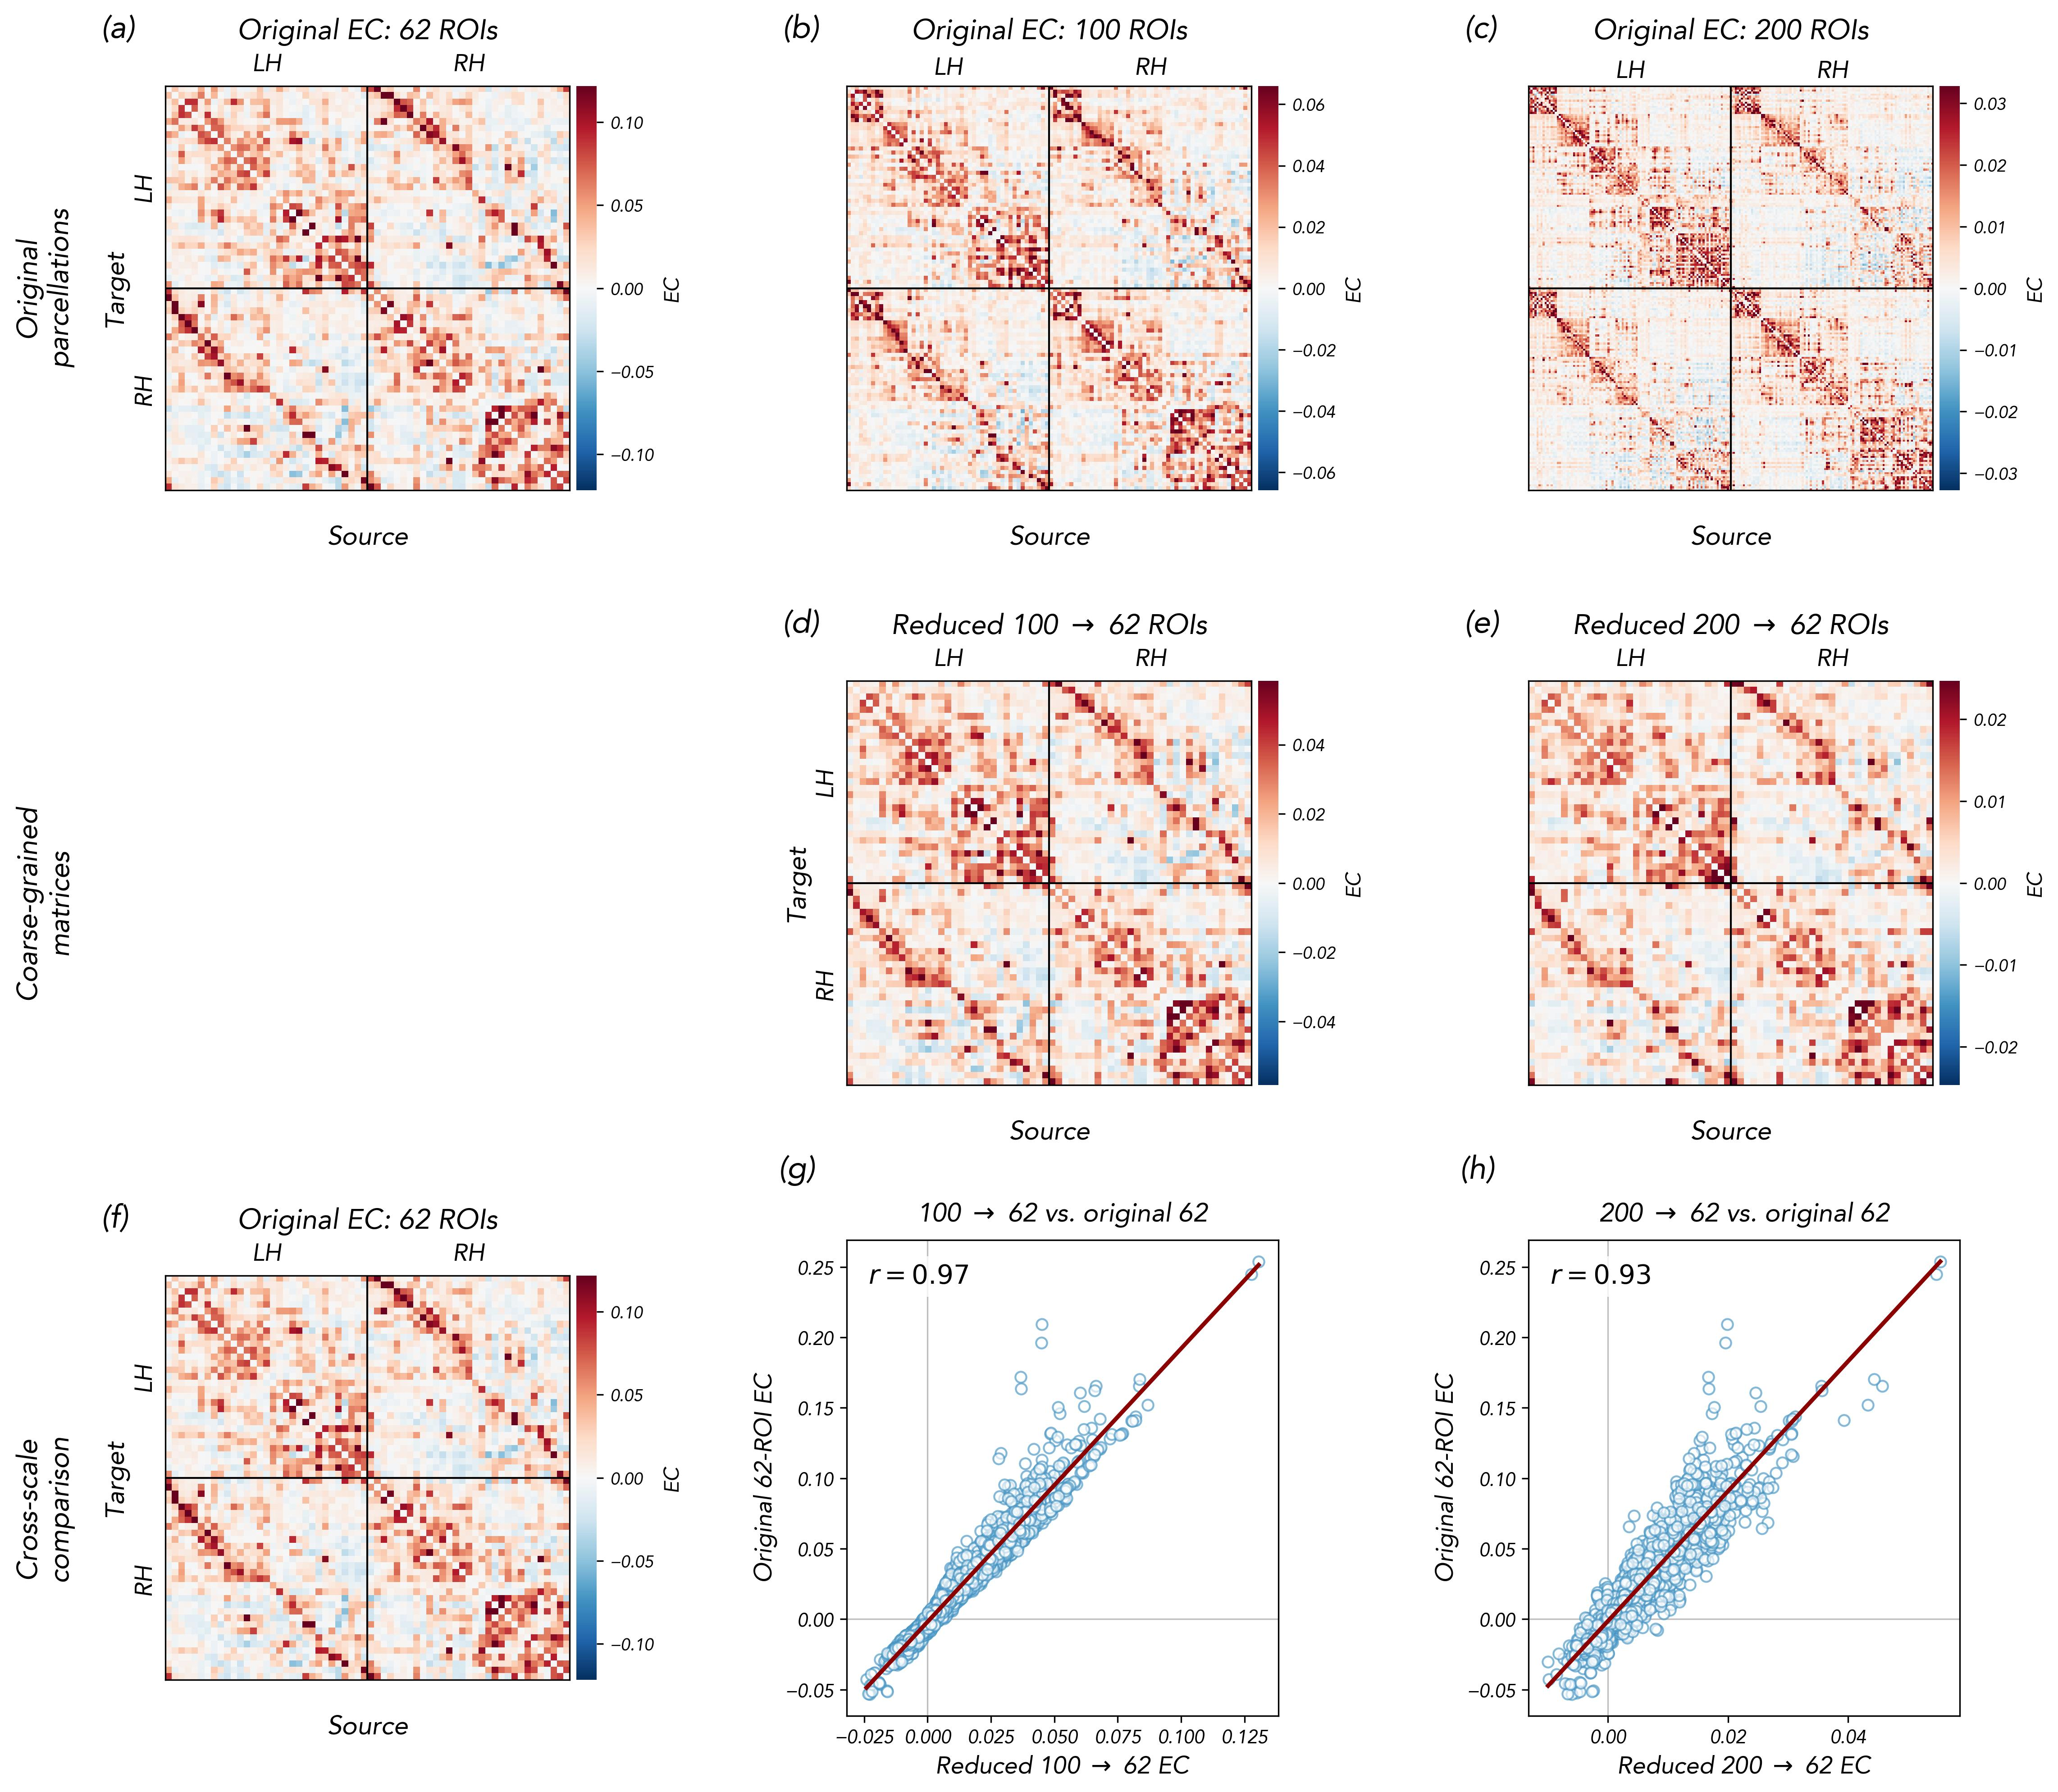

In [7]:
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
matrix_cmap = 'RdBu_r'
scatter_edgecolor = '#4393c3'
js = []
js.append(dediag(np.mean(JS_62_1[:, :62, :62], axis=0)))
js.append(dediag(np.mean(JS_100_1[:, :100, :100], axis=0)))
js.append(dediag(np.mean(JS_new[:, :200, :200], axis=0)))
js.append(dediag(cluster_regions_EC(js[1], aggregate[:100])))
js.append(dediag(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100])))
js.append(dediag(mapping_orig(js[2])))
original_62 = js[0]
original_100 = js[1]
original_200 = js[2]
reduced_100_to_62 = js[3]
reduced_200_to_62 = js[4]
reduced_200_to_100 = js[5]
perc = 99
original_vmax = [np.nanpercentile(np.abs(original_62), perc), np.nanpercentile(np.abs(original_100), perc), np.nanpercentile(np.abs(original_200), perc)]
comparison_62_vmax = [np.nanpercentile(np.abs(original_62), perc), np.nanpercentile(np.abs(reduced_100_to_62), perc), np.nanpercentile(np.abs(reduced_200_to_62), perc)]
fig, axes = plt.subplots(3, 3, figsize=(15, 14), gridspec_kw={'height_ratios': [1, 1, 1], 'width_ratios': [1, 1, 1], 'hspace': 0.25, 'wspace': 0.58})
original_matrices = [original_62, original_100, original_200]
original_titles = ['Original EC: 62 ROIs', 'Original EC: 100 ROIs', 'Original EC: 200 ROIs']
for column, (matrix, title) in enumerate(zip(original_matrices, original_titles)):
    ax = axes[0, column]
    im = plot_matrix_without_labels(matrix, ax, vmin=-original_vmax[column], vmax=original_vmax[column], cmap=matrix_cmap, xlabel='Source', ylabel='Target' if column == 0 else None, show_hemi_x=True, show_hemi_y=column == 0)
    ax.set_title(title, fontsize=15, pad=25)
    add_colorbar(fig, ax, im, label='EC')
axes[1, 0].axis('off')
reduced_matrices = [reduced_100_to_62, reduced_200_to_62]
reduced_titles = ['Reduced 100 $\\rightarrow$ 62 ROIs', 'Reduced 200 $\\rightarrow$ 62 ROIs']
for column, (matrix, title) in enumerate(zip(reduced_matrices, reduced_titles), start=1):
    ax = axes[1, column]
    im = plot_matrix_without_labels(matrix, ax, vmin=-comparison_62_vmax[column], vmax=comparison_62_vmax[column], cmap=matrix_cmap, xlabel='Source', ylabel='Target' if column == 1 else None, show_hemi_x=True, show_hemi_y=column == 1)
    ax.set_title(title, fontsize=15, pad=25)
    add_colorbar(fig, ax, im, label='EC')
ax = axes[2, 0]
im = plot_matrix_without_labels(original_62, ax, vmin=-comparison_62_vmax[0], vmax=comparison_62_vmax[0], cmap=matrix_cmap, xlabel='Source', ylabel='Target', show_hemi_x=True, show_hemi_y=True)
ax.set_title('Original EC: 62 ROIs', fontsize=15, pad=25)
add_colorbar(fig, ax, im, label='EC')
plot_edgewise_comparison(axes[2, 1], reduced_100_to_62, original_62, xlabel='Reduced 100 $\\rightarrow$ 62 EC', ylabel='Original 62-ROI EC', title='100 $\\rightarrow$ 62 vs. original 62', edgecolor=scatter_edgecolor)
plot_edgewise_comparison(axes[2, 2], reduced_200_to_62, original_62, xlabel='Reduced 200 $\\rightarrow$ 62 EC', ylabel='Original 62-ROI EC', title='200 $\\rightarrow$ 62 vs. original 62', edgecolor=scatter_edgecolor)
panel_positions = [(0, 0, '(a)'), (0, 1, '(b)'), (0, 2, '(c)'), (1, 1, '(d)'), (1, 2, '(e)'), (2, 0, '(f)'), (2, 1, '(g)'), (2, 2, '(h)')]
for row, column, label in panel_positions:
    axes[row, column].text(-0.16, 1.18, label, transform=axes[row, column].transAxes, fontsize=17, fontweight='bold', va='top', ha='left')
fig.text(0.025, 0.825, 'Original\nparcellations', rotation=90, ha='center', va='center', fontsize=15, fontweight='bold')
fig.text(0.025, 0.5, 'Coarse-grained\nmatrices', rotation=90, ha='center', va='center', fontsize=15, fontweight='bold')
fig.text(0.025, 0.18, 'Cross-scale\ncomparison', rotation=90, ha='center', va='center', fontsize=15, fontweight='bold')
plt.subplots_adjust(top=0.95, bottom=0.07, left=0.085, right=0.97)
plt.savefig(OUTPUT / 'EC_cross_parcellation_comparison.jpg', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT / 'figure_3.pdf', bbox_inches='tight')
plt.show()